In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
data=pd.read_excel("us_retail_sales_2020_2025.xlsx")
data

,naics_code,kind_of_business,sales_month,sales,estimate_type
0,45291,Warehouse clubs and superstores,1992-01-01,2579.0,not adjusted
1,NaN,Retail sales and food services excl motor vehi...,1992-01-01,117814.0,adjusted
2,NaN,Retail sales and food services excl gasoline s...,1992-01-01,151292.0,adjusted
3,NaN,Retail sales and food services excl motor vehi...,1992-01-01,130617.0,adjusted
4,NaN,"Retail and food services sales, total",1992-01-01,164095.0,adjusted
...,...,...,...,...,...
40474,44811,Men's clothing stores,2024-09-01,NaN,not adjusted
40475,4481,Clothing stores,2024-09-01,16569.0,not adjusted
40476,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
40477,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [17]:
data = data[data["estimate_type"] == "not adjusted"].copy()
data.columns = (data.columns.str.strip().str.title())
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,45291,Warehouse clubs and superstores,1992-01-01,2579.0,not adjusted
5,44811,Men's clothing stores,1992-01-01,701.0,not adjusted
6,44812,Women's clothing stores,1992-01-01,1873.0,not adjusted
7,44814,Family clothing stores,1992-01-01,1649.0,not adjusted
8,44819,Other clothing stores,1992-01-01,NaN,not adjusted
...,...,...,...,...,...
40474,44811,Men's clothing stores,2024-09-01,NaN,not adjusted
40475,4481,Clothing stores,2024-09-01,16569.0,not adjusted
40476,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
40477,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [18]:
display(data.isna().sum())

Naics_Code          2751
Kind_Of_Business       0
Sales_Month            0
Sales                900
Estimate_Type          0
dtype: int64

In [19]:
data.info()

<class 'pandas.DataFrame'>
Index: 25545 entries, 0 to 40478
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Naics_Code        22794 non-null  object        
 1   Kind_Of_Business  25545 non-null  str           
 2   Sales_Month       25545 non-null  datetime64[us]
 3   Sales             24645 non-null  float64       
 4   Estimate_Type     25545 non-null  str           
dtypes: datetime64[us](1), float64(1), object(1), str(2)
memory usage: 1.2+ MB


In [20]:
print(data["Naics_Code"].unique())

[45291 44811 44812 44814 44819 4482 44831 451 45111 45112 451211 452
 452111 452112 4529 45299 453 4532 45321 45322 45330 454 4541 45431 722
 7224 4521 722511 '722513, 722514, 722515' 7225 4453 nan 441 44114412 4411
 44111 44112 4413 442443 442 4421 4422 44221 44511 44413 446 44611 447 448
 4481 4441 444 443142 443141 443 442299 44412 4451 445]


In [21]:
data = data.dropna(subset=["Naics_Code"])

In [22]:
data = data.dropna(subset=["Sales"])

In [23]:
data=data.reset_index(drop=True)
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,45291,Warehouse clubs and superstores,1992-01-01,2579.0,not adjusted
1,44811,Men's clothing stores,1992-01-01,701.0,not adjusted
2,44812,Women's clothing stores,1992-01-01,1873.0,not adjusted
3,44814,Family clothing stores,1992-01-01,1649.0,not adjusted
4,4482,Shoe stores,1992-01-01,1206.0,not adjusted
...,...,...,...,...,...
21889,44812,Women's clothing stores,2024-09-01,2673.0,not adjusted
21890,4481,Clothing stores,2024-09-01,16569.0,not adjusted
21891,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
21892,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [24]:
data=data[data["Naics_Code"]!= 447 ]
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,45291,Warehouse clubs and superstores,1992-01-01,2579.0,not adjusted
1,44811,Men's clothing stores,1992-01-01,701.0,not adjusted
2,44812,Women's clothing stores,1992-01-01,1873.0,not adjusted
3,44814,Family clothing stores,1992-01-01,1649.0,not adjusted
4,4482,Shoe stores,1992-01-01,1206.0,not adjusted
...,...,...,...,...,...
21889,44812,Women's clothing stores,2024-09-01,2673.0,not adjusted
21890,4481,Clothing stores,2024-09-01,16569.0,not adjusted
21891,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
21892,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [25]:
print(data["Naics_Code"].unique())

[45291 44811 44812 44814 4482 44831 451 45111 45112 451211 452 452111
 452112 4529 45299 453 4532 45321 45322 45330 454 4541 45431 722 7224 4521
 722511 '722513, 722514, 722515' 7225 4453 441 44114412 4411 44111 44112
 4413 442443 442 4421 4422 44221 44413 446 44611 448 4481 4441 444 443141
 443 4451 445 443142 44412 44511 442299 44819]


In [26]:
data['Estimate_Type']=data['Estimate_Type'].replace('not adjusted','not_adjusted')
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,45291,Warehouse clubs and superstores,1992-01-01,2579.0,not_adjusted
1,44811,Men's clothing stores,1992-01-01,701.0,not_adjusted
2,44812,Women's clothing stores,1992-01-01,1873.0,not_adjusted
3,44814,Family clothing stores,1992-01-01,1649.0,not_adjusted
4,4482,Shoe stores,1992-01-01,1206.0,not_adjusted
...,...,...,...,...,...
21889,44812,Women's clothing stores,2024-09-01,2673.0,not_adjusted
21890,4481,Clothing stores,2024-09-01,16569.0,not_adjusted
21891,448,Clothing and clothing access. stores,2024-09-01,23142.0,not_adjusted
21892,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not_adjusted


In [35]:
import plotly.express as px
# 1. Group by month and sum the sales across all categories
df_trend = (
    data[data["Estimate_Type"] == "not_adjusted"]
    .dropna(subset=["Sales"])
    .groupby("Sales_Month", as_index=False)["Sales"]
    .sum()
)

# 2. Create the trend line
fig = px.line(
    df_trend,
    x="Sales_Month",
    y="Sales",
    title="Total US Retail Sales Trend Over Time (All Categories Combined)",
    labels={"Sales_Month": "Date", "Sales": "Total Sales ($ Millions)"},
    template="plotly_white",
)

fig.update_layout(hovermode="x unified")
fig.show()


In [32]:

# Convert Sales_Month to datetime to easily extract Year and Month
df_trend["Sales_Month"] = pd.to_datetime(df_trend["Sales_Month"])
df_trend["Year"] = df_trend["Sales_Month"].dt.year
df_trend["Month"] = df_trend["Sales_Month"].dt.month

# 3. Calculate Annual Total Sales per year
annual_totals = (
    df_trend.groupby("Year")["Sales"]
    .sum()
    .reset_index()
    .rename(columns={"Sales": "Annual_Total"})
)

# 4. Calculate Nov (Month 11) + Dec (Month 12) total sales per year
nov_dec_df = df_trend[df_trend["Month"].isin([11, 12])]
nov_dec_totals = (
    nov_dec_df.groupby("Year")["Sales"]
    .sum()
    .reset_index()
    .rename(columns={"Sales": "Nov_Dec_Total"})
)

# 5. Merge and compute percentage share
df_share = pd.merge(nov_dec_totals, annual_totals, on="Year")
df_share["Share_Pct"] = (df_share["Nov_Dec_Total"] / df_share["Annual_Total"]) * 100
df_share["Share_Text"] = df_share["Share_Pct"].round(1).astype(str) + "%"

# Filter for years 2020 to 2023 (or whatever full years are available)
df_share = df_share[
    (df_share["Year"] >= 2020) & (df_share["Year"] <= 2024)
]

# 6. Create the Bar Chart using Plotly Graph Objects for precise annotation control
fig = go.Figure()

# Add the main bars
fig.add_trace(
    go.Bar(
        x=df_share["Year"].astype(str),
        y=df_share["Share_Pct"],
        text=df_share["Share_Text"],
        textposition="outside",
        marker_color="#b86b35",  # Warm brownish-orange color matching your screenshot
        width=0.6,
    )
)

# Add horizontal dashed line for "even spread" (16.7% since 2 months out of 12 = 16.67%)
even_spread = (2 / 12) * 100
fig.add_shape(
    type="line",
    x0=-0.5,
    x1=len(df_share) - 0.5,
    y0=even_spread,
    y1=even_spread,
    line=dict(color="rgba(80, 110, 140, 0.8)", width=2, dash="dash"),
)

# Add annotation for the even spread line
fig.add_annotation(
    x=3.8,
    y=even_spread,
    text=f"even spread ({even_spread:.1f}%)",
    showarrow=False,
    yshift=2,
    font=dict(color="rgba(80, 110, 140, 0.9)", size=12),
)

# 7. Layout styling matching the clean look of the screenshot
fig.update_layout(
    title=dict(
        text="<b>Nov + Dec share of annual total retail sales</b>",
        font=dict(size=18, color="black"),
    ),
    xaxis=dict(title="", tickfont=dict(size=14)),
    yaxis=dict(
        title="",
        range=[0, 22],
        tickformat=".0f",
        ticksuffix="%",
        dtick=3,
        showgrid=True,
        gridcolor="rgba(210, 215, 220, 0.5)",
    ),
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=False,
    margin=dict(t=60, b=40, l=40, r=40),
)

fig.show()

In [33]:
# 3. Classify months into groups: "Nov-Dec" vs "Jan-Oct"
df_trend["Period_Group"] = df_trend["Month"].apply(
    lambda m: "Nov-Dec" if m in [11, 12] else "Jan-Oct"
)

# 4. Aggregate sales by Year and Period_Group
df_grouped = (
    df_trend.groupby(["Year", "Period_Group"])["Sales"]
    .sum()
    .reset_index()
)

# 5. Calculate YoY Growth (%) relative to the previous year for each group
df_grouped["Prior_Sales"] = df_grouped.groupby("Period_Group")["Sales"].shift(1)
df_grouped["YoY_Growth"] = (
    (df_grouped["Sales"] - df_grouped["Prior_Sales"]) / df_grouped["Prior_Sales"]
) * 100

# Format text labels with percentage sign
df_grouped["Growth_Text"] = df_grouped["YoY_Growth"].round(1).astype(str) + "%"

# Filter for years 2021 to 2023 (since 2020 is needed as base year for YoY calculation)
df_filtered = df_grouped[
    (df_grouped["Year"] >= 2021) & (df_grouped["Year"] <= 2023)
]

# 6. Create the Grouped Bar Chart using Plotly Graph Objects
fig = go.Figure()

# Colors matching the image: Brown/Orange for Nov-Dec, Blue for Jan-Oct
colors = {"Nov-Dec": "#b86b35", "Jan-Oct": "#2b5c8f"}

for period in ["Nov-Dec", "Jan-Oct"]:
    df_subset = df_filtered[df_filtered["Period_Group"] == period]
    fig.add_trace(
        go.Bar(
            x=df_subset["Year"].astype(str),
            y=df_subset["YoY_Growth"],
            name=period,
            text=df_subset["Growth_Text"],
            textposition="outside",
            marker_color=colors[period],
            width=0.35,
        )
    )

# 7. Layout styling
fig.update_layout(
    title=dict(
        text="<b>Holiday season vs. rest-of-year growth</b>",
        font=dict(size=18, color="black"),
    ),
    xaxis=dict(title="year", tickfont=dict(size=14)),
    yaxis=dict(
        title="YoY growth (%)",
        range=[0, 21],
        tickformat=".1f",
        ticksuffix="%",
        dtick=2.5,
        showgrid=True,
        gridcolor="rgba(210, 215, 220, 0.5)",
    ),
    barmode="group",
    plot_bgcolor="white",
    paper_bgcolor="white",
    legend=dict(
        x=0.78,
        y=0.95,
        bgcolor="rgba(255,255,255,0.8)",
        bordercolor="rgba(200,200,200,0.5)",
        borderwidth=1,
    ),
    margin=dict(t=60, b=40, l=50, r=40),
)

fig.show()

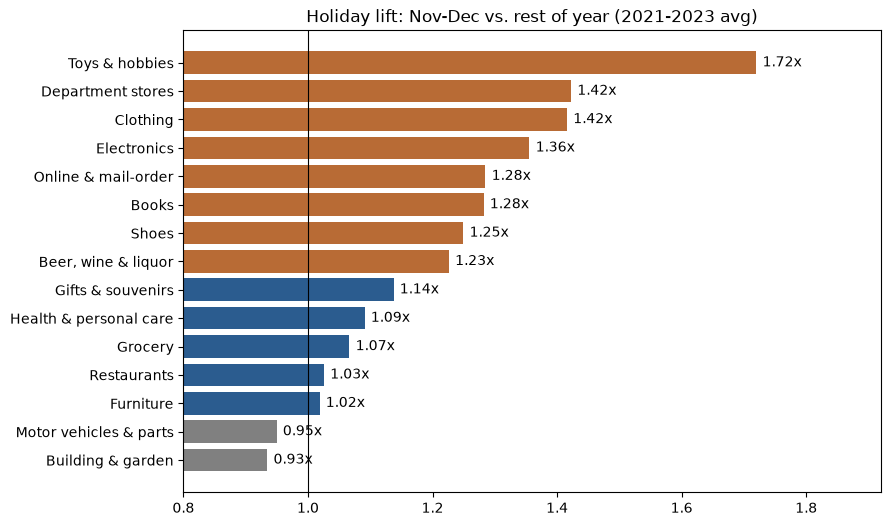

In [34]:
import matplotlib.pyplot as plt
cats = {
    "Hobby, toy, and game stores": "Toys & hobbies",
    "Book stores": "Books",
    "Department stores": "Department stores",
    "Electronics stores": "Electronics",
    "Clothing stores": "Clothing",
    "Shoe stores": "Shoes",
    "Gift, novelty, and souvenir stores": "Gifts & souvenirs",
    "Electronic shopping and mail-order houses": "Online & mail-order",
    "Beer, wine, and liquor stores": "Beer, wine & liquor",
    "Furniture stores": "Furniture",
    "Grocery stores": "Grocery",
    "Health and personal care stores": "Health & personal care",
    "Restaurants and other eating places": "Restaurants",
    "Building mat. and garden equip. and supplies dealers": (
        "Building & garden"
    ),
    
    "Motor vehicle and parts dealers": "Motor vehicles & parts",
}

data["Sales_Month"] = pd.to_datetime(data["Sales_Month"])

base = data[
    data.Sales_Month.dt.year.between(2021, 2023)
    & data.Kind_Of_Business.isin(cats.keys())
].copy()
base["cat"] = base["Kind_Of_Business"].map(cats)
base["hol"] = (
    base.Sales_Month.dt.month.isin([11, 12])
    .map({True: "Holiday", False: "Rest"})
)

m = base.groupby(["cat", "hol"])["Sales"].mean().unstack()
lift = (m["Holiday"] / m["Rest"]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    lift.index,
    lift,
    color=[
        "#b86b35" if v > 1.15 else ("#2b5c8f" if v >= 1 else "gray")
        for v in lift
    ],
)
ax.axvline(1, color="k", lw=0.8)

for i, v in enumerate(lift):
  ax.text(v + 0.01, i, f"{v:.2f}x", va="center")

ax.set_title("Holiday lift: Nov-Dec vs. rest of year (2021-2023 avg)")
ax.set_xlim(0.8, lift.max() + 0.2)
plt.show()
